# Forecast the next 6 weeks of sales and customers

**Backtest first.** Hold out the last 6 weeks of history (June 20 to July 31, 2015), train only on what came
before, and compare a gradient-boosted model (LightGBM) against two simple baselines a planner might use.
Then retrain on everything and forecast the real future window, using the promotion calendar the company
already knows.

The model predicts two things: **sales** (the headline forecast) and **customer traffic** (what the
staffing plan in notebook 03 needs).

In [1]:
from pathlib import Path

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from features import FEATURES, add_features, bias, rmspe, wape

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
PROCESSED = ROOT / "data" / "processed"
APP_DATA = ROOT / "app_data"
IMAGES = ROOT / "images"
APP_DATA.mkdir(exist_ok=True)

opened = pd.read_parquet(PROCESSED / "sales_open_days.parquet")
stores = pd.read_parquet(PROCESSED / "stores.parquet")
future = pd.read_parquet(PROCESSED / "future_calendar.parquet")

data = add_features(opened, stores)
HOLDOUT_START = pd.Timestamp("2015-06-20")
VALID_START = HOLDOUT_START - pd.Timedelta(days=42)

train = data[data["Date"] < HOLDOUT_START]
holdout = data[data["Date"] >= HOLDOUT_START].copy()
print(f"Training: {len(train):,} store-days to {train['Date'].max().date()}")
print(f"Holdout:  {len(holdout):,} store-days, {holdout['Date'].min().date()} to {holdout['Date'].max().date()}")

Training: 804,056 store-days to 2015-06-19
Holdout:  40,282 store-days, 2015-06-20 to 2015-07-31


### Baselines
1. **Recent average:** each store's average for that weekday over the last 6 weeks before the holdout.
2. **Weekday x promo average:** each store's average for that weekday, split by promo vs. no promo, over the
   last 52 weeks. This one knows promotions matter.

In [2]:
recent = train[train["Date"] >= VALID_START]
recent_avg = recent.groupby(["Store", "DayOfWeek"], observed=True)[["Sales", "Customers"]].mean()

last_year = train[train["Date"] >= HOLDOUT_START - pd.Timedelta(weeks=52)]
promo_avg = last_year.groupby(["Store", "DayOfWeek", "Promo"], observed=True)[["Sales", "Customers"]].mean()

keys = ["Store", "DayOfWeek"]
for target in ["Sales", "Customers"]:
    holdout[f"{target}_recent_avg"] = holdout.join(recent_avg[target].rename("p"), on=keys)["p"]
    holdout[f"{target}_promo_avg"] = holdout.join(promo_avg[target].rename("p"), on=keys + ["Promo"])["p"]
    holdout[f"{target}_promo_avg"] = holdout[f"{target}_promo_avg"].fillna(holdout[f"{target}_recent_avg"])
holdout[[c for c in holdout.columns if c.endswith("_avg")]].isna().sum()

Sales_recent_avg        0
Sales_promo_avg         0
Customers_recent_avg    0
Customers_promo_avg     0
dtype: int64

### LightGBM
Trained on log sales (errors become relative, like the business cares about), with the store as a
categorical feature. Early stopping uses the last 6 weeks *before* the holdout, so the holdout stays
untouched.

In [3]:
PARAMS = dict(
    objective="regression",
    learning_rate=0.05,
    num_leaves=127,
    min_child_samples=40,
    feature_fraction=0.8,
    bagging_fraction=0.8,
    bagging_freq=1,
    max_cat_to_onehot=4,
    cat_smooth=10,
    verbose=-1,
    seed=42,
)


def fit(target, rows, valid_rows=None, rounds=5000):
    train_set = lgb.Dataset(rows[FEATURES], np.log1p(rows[target]), categorical_feature=["Store"])
    if valid_rows is None:
        return lgb.train(PARAMS, train_set, num_boost_round=rounds)
    valid_set = lgb.Dataset(valid_rows[FEATURES], np.log1p(valid_rows[target]), reference=train_set)
    return lgb.train(PARAMS, train_set, num_boost_round=rounds, valid_sets=[valid_set],
                     callbacks=[lgb.early_stopping(100, verbose=False)])


inner_train = train[train["Date"] < VALID_START]
inner_valid = train[train["Date"] >= VALID_START]
best_rounds = {}
models = {}
for target in ["Sales", "Customers"]:
    finder = fit(target, inner_train, inner_valid)
    best_rounds[target] = finder.best_iteration
    models[target] = fit(target, train, rounds=best_rounds[target])
    holdout[f"{target}_model"] = np.expm1(models[target].predict(holdout[FEATURES]))
best_rounds

{'Sales': 528, 'Customers': 467}

In [4]:
rows = []
for target in ["Sales", "Customers"]:
    for method, label in [("recent_avg", "Recent average"), ("promo_avg", "Weekday x promo average"), ("model", "LightGBM")]:
        actual, predicted = holdout[target], holdout[f"{target}_{method}"]
        rows.append({
            "target": target,
            "method": label,
            "WAPE": round(wape(actual, predicted), 4),
            "RMSPE": round(rmspe(actual, predicted), 4),
            "bias": round(bias(actual, predicted), 4),
        })
metrics = pd.DataFrame(rows)
metrics

,target,method,WAPE,RMSPE,bias
0,Sales,Recent average,0.1805,0.2481,0.0441
1,Sales,Weekday x promo average,0.0981,0.1382,0.0005
2,Sales,LightGBM,0.0868,0.1266,0.0009
3,Customers,Recent average,0.1185,0.1645,0.0508
4,Customers,Weekday x promo average,0.0859,0.1216,0.0274
5,Customers,LightGBM,0.0684,0.1010,0.0094


### Finding: accuracy
LightGBM beats both baselines on both targets. **Sales: 8.7% WAPE** vs. 9.8% for the weekday x promo
average and 18.1% for the recent average. **Customers: 6.8%** vs. 8.6% and 11.9%. Bias is close to zero
(+0.1% for sales), so the forecast does not systematically over- or under-predict. The weekday x promo
baseline is strong because promotions drive so much of the variation; the model adds store-specific
patterns and calendar effects on top. On RMSPE, the Kaggle competition metric, the model scores 0.127.

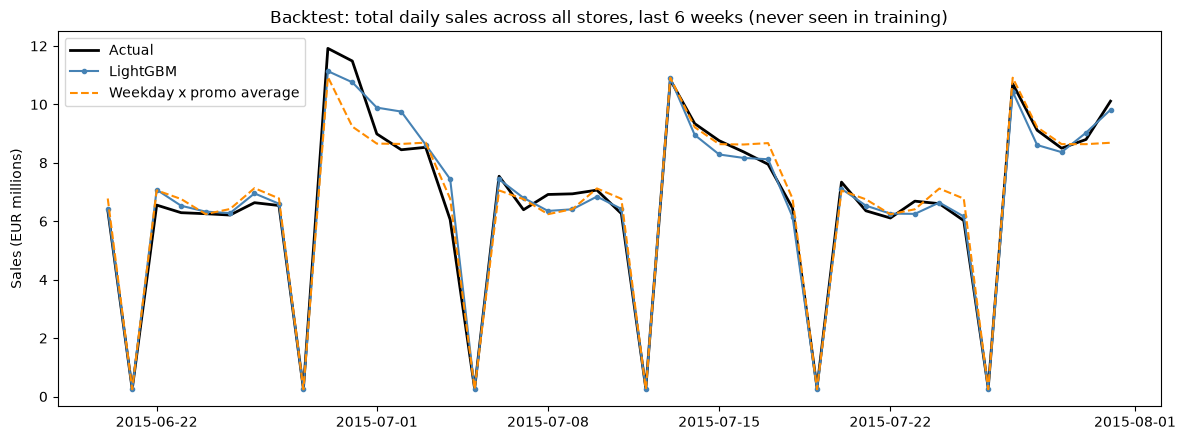

In [5]:
daily = holdout.groupby("Date")[["Sales", "Sales_model", "Sales_promo_avg"]].sum() / 1e6
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(daily.index, daily["Sales"], color="black", linewidth=2, label="Actual")
ax.plot(daily.index, daily["Sales_model"], color="steelblue", marker="o", markersize=3, label="LightGBM")
ax.plot(daily.index, daily["Sales_promo_avg"], color="darkorange", linestyle="--", label="Weekday x promo average")
ax.set_title("Backtest: total daily sales across all stores, last 6 weeks (never seen in training)")
ax.set_ylabel("Sales (EUR millions)")
ax.legend()
plt.tight_layout()
plt.savefig(IMAGES / "backtest_total_sales.png", dpi=150, bbox_inches="tight")
plt.show()

In [6]:
store_accuracy = holdout.groupby("Store", observed=True).apply(
    lambda g: pd.Series({
        "sales_wape": wape(g["Sales"], g["Sales_model"]),
        "customers_wape": wape(g["Customers"], g["Customers_model"]),
        "avg_daily_sales": g["Sales"].mean(),
    }),
    include_groups=False,
).reset_index()
print(store_accuracy[["sales_wape", "customers_wape"]].describe(percentiles=[0.5, 0.9, 0.99]).round(3))

       sales_wape  customers_wape
count    1115.000        1115.000
mean        0.088           0.069
std         0.030           0.024
min         0.040           0.034
50%         0.084           0.065
90%         0.112           0.090
99%         0.186           0.149
max         0.508           0.337


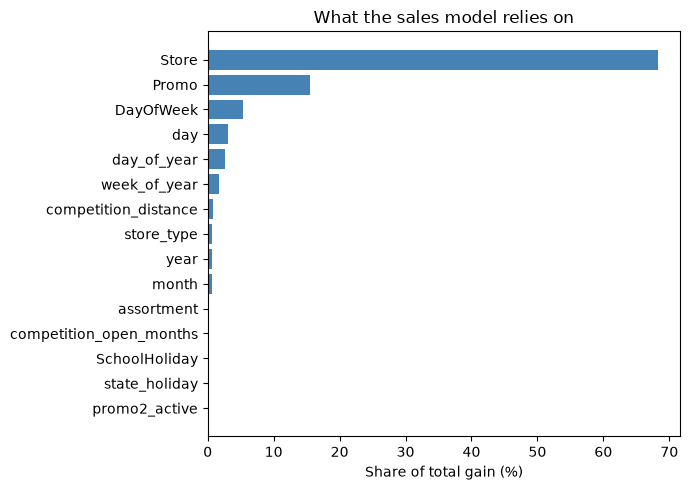

In [7]:
importance = pd.DataFrame({
    "feature": FEATURES,
    "gain_share": models["Sales"].feature_importance("gain") / models["Sales"].feature_importance("gain").sum(),
}).sort_values("gain_share")
fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(importance["feature"], importance["gain_share"] * 100, color="steelblue")
ax.set_xlabel("Share of total gain (%)")
ax.set_title("What the sales model relies on")
plt.tight_layout()
plt.savefig(IMAGES / "feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()

### Retrain on everything and forecast the future window
Same settings, all history through July 31, 2015. The future calendar (from Kaggle's test file) says which
stores open on which days and when promotions run. Closed days get a forecast of zero. 11 rows for store
622 have no "Open" value; the store was open on the surrounding days, so they are treated as open.

In [8]:
future = future.copy()
future["Open"] = future["Open"].fillna(1).astype(int)
future_features = add_features(future, stores)

final = {}
for target in ["Sales", "Customers"]:
    rounds = int(best_rounds[target] * len(data) / len(train))
    final[target] = fit(target, data, rounds=rounds)
    future_features[f"forecast_{target.lower()}"] = np.where(
        future_features["Open"] == 1, np.expm1(final[target].predict(future_features[FEATURES])), 0
    )

forecast = future_features[["Store", "Date", "DayOfWeek", "Open", "Promo", "StateHoliday", "SchoolHoliday",
                            "forecast_sales", "forecast_customers"]].copy()
forecast["Store"] = forecast["Store"].astype(int)
forecast = forecast.sort_values(["Store", "Date"])
print(f"{forecast['Store'].nunique()} stores, {forecast['Date'].nunique()} days")
print(f"Forecast total sales: {forecast['forecast_sales'].sum() / 1e6:,.1f}M EUR")
forecast.head(8).round({"forecast_sales": 0, "forecast_customers": 0})

856 stores, 48 days
Forecast total sales: 241.3M EUR


,Store,Date,DayOfWeek,Open,Promo,StateHoliday,SchoolHoliday,forecast_sales,forecast_customers
40232,1,2015-08-01,6,1,0,0,1,4731.0,523.0
39376,1,2015-08-02,7,0,0,0,1,0.0,0.0
38520,1,2015-08-03,1,1,1,0,1,5816.0,612.0
37664,1,2015-08-04,2,1,1,0,1,4978.0,527.0
36808,1,2015-08-05,3,1,1,0,1,4630.0,515.0
35952,1,2015-08-06,4,1,1,0,1,4467.0,502.0
35096,1,2015-08-07,5,1,1,0,1,4468.0,502.0
34240,1,2015-08-08,6,1,0,0,1,4083.0,483.0


In [9]:
history_start = pd.Timestamp("2015-05-01")
recent_history = opened[opened["Date"] >= history_start][["Store", "Date", "Sales", "Customers", "Promo"]]

forecast.to_parquet(PROCESSED / "forecast_future.parquet", index=False)
forecast.round({"forecast_sales": 1, "forecast_customers": 1}).to_csv(APP_DATA / "forecast_future.csv", index=False)
holdout_out = holdout[["Store", "Date", "Promo", "Sales", "Sales_model", "Customers", "Customers_model"]].copy()
holdout_out["Store"] = holdout_out["Store"].astype(int)
holdout_out.round({"Sales_model": 1, "Customers_model": 1}).to_csv(APP_DATA / "backtest.csv", index=False)
recent_history.to_csv(APP_DATA / "history.csv", index=False)
metrics.to_csv(APP_DATA / "metrics.csv", index=False)
store_accuracy.assign(Store=store_accuracy["Store"].astype(int)).round(4).to_csv(APP_DATA / "store_accuracy.csv", index=False)
importance.round(4).to_csv(APP_DATA / "feature_importance.csv", index=False)
for f in sorted(APP_DATA.glob("*.csv")):
    print(f"{f.name}: {f.stat().st_size / 1e6:.1f} MB")

backtest.csv: 1.6 MB
feature_importance.csv: 0.0 MB
forecast_future.csv: 1.6 MB
history.csv: 2.3 MB
metrics.csv: 0.0 MB
staffing_all_stores.csv: 0.0 MB
store_accuracy.csv: 0.0 MB


### Summary
- **Backtest on 6 unseen weeks (40,282 store-days):** sales WAPE 8.7%, customers WAPE 6.8%, near-zero
  bias, beating both baselines.
- **Store by store:** the median store's sales error is 8.4%, and 90% of stores are under 11.2%. A handful
  of stores exceed 20% and would deserve a manual look before trusting their forecast.
- **What drives it:** the store itself (68% of the model's gain), then promotions (16%) and weekday (5%);
  day of month and time of year add smaller effects.
- **The forecast:** 856 stores x 48 days (August 1 to September 17, 2015), 241.3M EUR in total sales,
  using the promotion calendar the company already planned. Saved for the staffing plan and the app.